# Cell constraint tree and layout links

Create a `Cell` containing a cellbox, contact, metal1 and poly rectangle. Extract the actual X/Y constraint graphs and inspect their links on the layout.

- Install the notebook extra with `pip install -e ".[notebooks]"` and select that Python environment.
- Run all cells from the repository root or the notebooks directory.
- Coordinates and rule values are in the loader's nanometre database units. The SCMOS catalog is loaded unchanged; this is an illustration of the extracted rules, not a complete process DRC certification.
- `Cell` has no dedicated cellbox field. Here it is a synthetic rectangle on `INSTANCE_BOUNDARY_LAYER`, with explicit zero-margin containment constraints (not foundry rules).
- The underlying constraints form directed graphs, not necessarily trees. The inspection tree groups every edge by axis, kind and rule ID.
- Click a numbered arrow to inspect its tree entry; click an entry to return to its arrow. Hover over a link for its inequality.


In [1]:
from collections import defaultdict
from html import escape
from pathlib import Path

from IPython.display import HTML, SVG, display

from gds_migrator.constraints.graph import ConstraintGraph
from gds_migrator.constraints.plane_sweep import Rectangle, generate_axis_constraints
from gds_migrator.hierarchy.migrator import INSTANCE_BOUNDARY_LAYER
from gds_migrator.hierarchy.model import Cell
from gds_migrator.technology.rules import TechnologyRules

root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'src' / 'gds_migrator').is_dir()),
    None,
)
if root is None:
    raise FileNotFoundError('Run this notebook inside the player repository.')

tech = TechnologyRules.from_json(
    root / 'data' / 'scmos_180nm_mistral.json',
    layer_properties_path=root / 'data' / 'scmos_180nm_mosis.lyp',
)


In [2]:
def make_rectangle(
    name: str, bounds: tuple[float, float, float, float]
) -> Rectangle:
    xmin, xmax, ymin, ymax = bounds
    if not xmin < xmax or not ymin < ymax:
        raise ValueError('Rectangle bounds must have positive width and height.')
    layer, datatype = tech.layers[name]
    return Rectangle(name, layer, xmin, xmax, ymin, ymax, datatype)


cellbox = Rectangle('cellbox', INSTANCE_BOUNDARY_LAYER, 0, 18000, 0, 18000)
contact = make_rectangle('contact', (8000, 10000, 8000, 10000))
metal1 = make_rectangle('metal1', (6000, 12000, 7000, 11000))
poly = make_rectangle('poly', (4000, 14000, 6000, 12000))
cell = Cell(name='contact_stack', rectangles=[cellbox, contact, metal1, poly])
shapes = [contact, metal1, poly]
display(cell)


Cell(name='contact_stack', rectangles=[Rectangle(id='cellbox', layer=-1, xmin=0, xmax=18000, ymin=0, ymax=18000, datatype=0), Rectangle(id='contact', layer=25, xmin=8000, xmax=10000, ymin=8000, ymax=10000, datatype=0), Rectangle(id='metal1', layer=49, xmin=6000, xmax=12000, ymin=7000, ymax=11000, datatype=0), Rectangle(id='poly', layer=46, xmin=4000, xmax=14000, ymin=6000, ymax=12000, datatype=0)], instances=[], polygons=[])

In [3]:
graphs: dict[str, ConstraintGraph] = {}
initial_positions: dict[str, dict[str, float]] = {}
solved_positions: dict[str, dict[str, float]] = {}

for axis in ('x', 'y'):
    graph = generate_axis_constraints(cell.rectangles, tech, axis)
    for rect in shapes:
        for source, target, side in (
            (cellbox, rect, 'lo'), (rect, cellbox, 'hi')
        ):
            graph.add_constraint(
                f'{source.id}:{side}', f'{target.id}:{side}', 0,
                constraint_id=f'{axis}:cellbox:{rect.id}:{side}',
                metadata={
                    'kind': 'cellbox_containment', 'axis': axis,
                    'source_rect': source.id, 'target_rect': target.id,
                    'rule_value': 0, 'rule_id': 'cellbox',
                },
            )
    positions = {
        f'{rect.id}:{side}': getattr(rect, f'{axis}{bound}')
        for rect in cell.rectangles
        for side, bound in (('lo', 'min'), ('hi', 'max'))
    }
    solved = graph.solve(positions)
    assert solved == positions, 'The example must satisfy the extracted rules.'
    graphs[axis] = graph
    initial_positions[axis] = positions
    solved_positions[axis] = solved
    print(f'{axis.upper()}: {len(graph.nodes)} nodes, {len(graph.edges)} constraints')


X: 8 nodes, 13 constraints
Y: 8 nodes, 13 constraints


In [4]:
layer_colors = {
    'cellbox': '#64748b', 'poly': '#718e2d',
    'metal1': '#f9bd46', 'contact': '#cdc16b',
}
constraint_colors = {
    'minimum_width': '#2563eb', 'minimum_overlap': '#9333ea',
    'minimum_spacing': '#dc2626', 'minimum_extension': '#ea580c',
    'cellbox_containment': '#475569',
}
rectangles_by_id = {rect.id: rect for rect in cell.rectangles}


def boundary_midpoint(node: str, axis: str) -> tuple[float, float]:
    shape_id, side = node.rsplit(':', 1)
    rect = rectangles_by_id[shape_id]
    coordinate = getattr(rect, f"{axis}{'min' if side == 'lo' else 'max'}")
    if axis == 'x':
        return coordinate, (rect.ymin + rect.ymax) / 2
    return (rect.xmin + rect.xmax) / 2, coordinate


def screen_point(point: tuple[float, float], panel: int) -> tuple[float, float]:
    x, y = point
    scale = 400 / (cellbox.xmax - cellbox.xmin)
    return (
        70 + panel * 540 + (x - cellbox.xmin) * scale,
        470 - (y - cellbox.ymin) * scale,
    )


svg_parts = [
    '<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 1080 550" '
    'role="img" aria-label="Cell layout with X and Y constraint links">',
    '<rect width="1080" height="550" fill="white"/>',
    '<defs>',
]
for kind, color in constraint_colors.items():
    svg_parts.append(
        f'<marker id="arrow-{kind}" viewBox="0 0 10 10" refX="9" refY="5" '
        f'markerWidth="6" markerHeight="6" orient="auto-start-reverse">'
        f'<path d="M 0 0 L 10 5 L 0 10 z" fill="{color}"/></marker>'
    )
svg_parts.append('</defs>')
tree: dict[str, dict[str, dict[str, list[str]]]] = {}
constraint_count = 0
label_parts: list[str] = []

for panel, (axis, graph) in enumerate(graphs.items()):
    svg_parts.append(
        f'<text x="{270 + panel * 540}" y="30" text-anchor="middle" '
        f'font-size="20" fill="#0f172a">{axis.upper()} constraints (nm)</text>'
    )
    for rect in (cellbox, poly, metal1, contact):
        x, y = screen_point((rect.xmin, rect.ymax), panel)
        scale = 400 / (cellbox.xmax - cellbox.xmin)
        fill = 'none' if rect.id == 'cellbox' else layer_colors[rect.id]
        dash = 'stroke-dasharray="6 4"' if rect.id == 'cellbox' else ''
        svg_parts.append(
            f'<rect x="{x}" y="{y}" width="{(rect.xmax - rect.xmin) * scale}" '
            f'height="{(rect.ymax - rect.ymin) * scale}" fill="{fill}" '
            f'fill-opacity="0.35" stroke="{layer_colors[rect.id]}" {dash}>'
            f'<title>{escape(rect.id)}: layer {rect.layer}/{rect.datatype}</title></rect>'
        )
    groups: dict[str, dict[str, list[str]]] = defaultdict(lambda: defaultdict(list))
    for index, ((source, target, weight), constraint_id, metadata) in enumerate(
        zip(graph.edges, graph.edge_ids, graph.edge_metadata), start=1
    ):
        kind = metadata['kind']
        color = constraint_colors[kind]
        rule = metadata['rule_id'] or 'unlabelled'
        key = f'{axis}-{constraint_id}'
        label = f'{axis.upper()}{index}: {target} - {source} >= {weight:g} nm'
        if 'start' in metadata:
            start = metadata['start']['x'], metadata['start']['y']
            end = metadata['end']['x'], metadata['end']['y']
        else:
            start = boundary_midpoint(source, axis)
            end = boundary_midpoint(target, axis)
        x1, y1 = screen_point(start, panel)
        x2, y2 = screen_point(end, panel)
        bend = (index - (len(graph.edges) + 1) / 2) * 40
        cx = (x1 + x2) / 2 + (bend if axis == 'y' else 0)
        cy = (y1 + y2) / 2 + (bend if axis == 'x' else 0)
        svg_parts.append(
            f'<a id="link-{escape(key)}" href="#entry-{escape(key)}">'
            f'<title>{escape(label)}; {escape(kind)}; rule {escape(rule)}</title>'
            f'<path d="M {x1} {y1} Q {cx} {cy} {x2} {y2}" fill="none" '
            f'stroke="{color}" stroke-width="2" marker-end="url(#arrow-{kind})"/>'
            f'<circle cx="{x1}" cy="{y1}" r="2.5" fill="{color}"/></a>'
        )
        label_parts.append(
            f'<a href="#entry-{escape(key)}"><title>{escape(label)}</title>'
            f'<text x="{(x1 + 2 * cx + x2) / 4}" '
            f'y="{(y1 + 2 * cy + y2) / 4 - 4}" font-size="11" '
            f'fill="{color}" stroke="white" stroke-width="3" paint-order="stroke">'
            f'{axis.upper()}{index}</text></a>'
        )
        groups[kind][rule].append(
            f'<li id="entry-{escape(key)}"><a href="#link-{escape(key)}">'
            f'{escape(label)}</a> <code>{escape(constraint_id)}</code></li>'
        )
        constraint_count += 1
    tree[axis] = dict(groups)

for index, (name, color) in enumerate(layer_colors.items()):
    svg_parts.append(
        f'<text x="{60 + index * 230}" y="510" fill="{color}" font-size="16">'
        f'{name} ({rectangles_by_id[name].layer}/{rectangles_by_id[name].datatype})</text>'
    )
svg_parts.extend(label_parts)
svg_parts.append('</svg>')
layout_svg = ''.join(svg_parts)
tree_parts = [f'<h3>Constraint tree: {escape(cell.name)} ({constraint_count} links)</h3>']
for axis, groups in tree.items():
    tree_parts.append(f'<details open><summary>{axis.upper()}</summary>')
    for kind, rules in groups.items():
        tree_parts.append(
            f'<details open style="margin-left:20px"><summary '
            f'style="color:{constraint_colors[kind]}">{escape(kind)}</summary>'
        )
        for rule, entries in rules.items():
            tree_parts.append(
                f'<details open style="margin-left:20px"><summary>Rule {escape(rule)} '
                f'({len(entries)})</summary><ul>{"".join(entries)}</ul></details>'
            )
        tree_parts.append('</details>')
    tree_parts.append('</details>')

constraint_html = layout_svg + ''.join(tree_parts)
display(HTML(constraint_html))


## Standalone SVG image

The image below also provides an `image/svg+xml` output for export. Use the combined view above for the clickable constraint tree. Blue links denote minimum widths, purple links denote overlaps and grey links denote cellbox containment. Arrow endpoints use the boundary midpoints recorded by the extractor; curved paths only separate overlapping links visually.


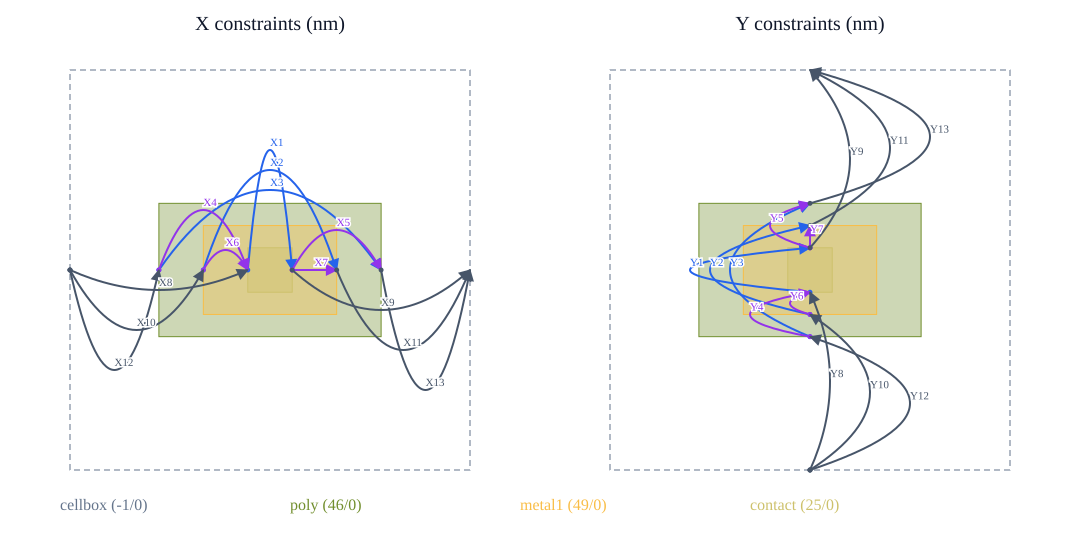

In [5]:
display(SVG(layout_svg))


## Sweep, migration and GDS exports

Both algorithms start independently from the original physical shapes. Sweep compacts boundary segments; migration uses the default longest-path solver and preserves already feasible coordinates. Consequently, migration is unchanged for this valid example, while sweep reduces its footprint.

The synthetic cellbox on layer -1 is excluded from both solver inputs and GDS exports. Its illustrative containment graph is not passed to the hierarchy solvers; resulting cell bounds are computed from the physical geometry.

Exports retain the SCMOS layer/datatype pairs from the `.lyp`: contact 25/0, metal1 49/0, poly 46/0. Coordinates use nanometres (`unit=1e-9`, `precision=1e-12`). Files are written to `notebooks/exports` and overwritten when the export cell is rerun. Each file is read back to verify layers and geometry.


In [6]:
from gds_migrator.constraints.segment_sweep import sweep_layout_with_polygons
from gds_migrator.hierarchy.migrator import MigratedCell, migrate_hierarchy
from gds_migrator.io.gdsii_reader import read_library
from gds_migrator.io.gdsii_writer import write_library

export_directory = root / 'notebooks' / 'exports'
physical_cell = Cell(
    name=cell.name,
    rectangles=[rect for rect in cell.rectangles if rect.id != cellbox.id],
    instances=list(cell.instances),
    polygons=list(cell.polygons),
)
source_cells = {physical_cell.name: physical_cell}
before_cells = {
    physical_cell.name: MigratedCell(
        name=physical_cell.name,
        rectangles=tuple(physical_cell.rectangles),
        instances=tuple(physical_cell.instances),
        polygons=tuple(physical_cell.polygons),
        xmin=min(rect.xmin for rect in physical_cell.rectangles),
        xmax=max(rect.xmax for rect in physical_cell.rectangles),
        ymin=min(rect.ymin for rect in physical_cell.rectangles),
        ymax=max(rect.ymax for rect in physical_cell.rectangles),
    )
}


In [7]:
swept_cells = migrate_hierarchy(
    source_cells, tech, layout_solver=sweep_layout_with_polygons,
)
swept_cell = swept_cells[physical_cell.name]
display(swept_cell)


MigratedCell(name='contact_stack', rectangles=(Rectangle(id='contact', layer=25, xmin=6000, xmax=8000, ymin=8000, ymax=10000, datatype=0), Rectangle(id='metal1', layer=49, xmin=4005, xmax=9000, ymin=6005, ymax=11000, datatype=0), Rectangle(id='poly', layer=46, xmin=4000, xmax=10000, ymin=6000, ymax=12000, datatype=0)), instances=(), xmin=4000, xmax=10000, ymin=6000, ymax=12000, polygons=())

In [8]:
migrated_cells = migrate_hierarchy(source_cells, tech)
migrated_cell = migrated_cells[physical_cell.name]
display(migrated_cell)

results = {'before': before_cells, 'after_sweep': swept_cells,
           'after_migration': migrated_cells}
for stage, cells in results.items():
    result = cells[physical_cell.name]
    print(f'{stage}: bounds=({result.xmin:g}, {result.ymin:g}) -> '
          f'({result.xmax:g}, {result.ymax:g}) nm')


MigratedCell(name='contact_stack', rectangles=(Rectangle(id='contact', layer=25, xmin=8000, xmax=10000, ymin=8000, ymax=10000, datatype=0), Rectangle(id='metal1', layer=49, xmin=6000, xmax=12000, ymin=7000, ymax=11000, datatype=0), Rectangle(id='poly', layer=46, xmin=4000, xmax=14000, ymin=6000, ymax=12000, datatype=0)), instances=(), xmin=4000, xmax=14000, ymin=6000, ymax=12000, polygons=())

before: bounds=(4000, 6000) -> (14000, 12000) nm
after_sweep: bounds=(4000, 6000) -> (10000, 12000) nm
after_migration: bounds=(4000, 6000) -> (14000, 12000) nm


In [9]:
expected_layers = {tech.layers[name] for name in ('contact', 'metal1', 'poly')}
export_directory.mkdir(parents=True, exist_ok=True)
export_paths: dict[str, Path] = {}
export_rows = []

for stage, cells in results.items():
    result = cells[physical_cell.name]
    actual_layers = {(rect.layer, rect.datatype) for rect in result.rectangles}
    if actual_layers != expected_layers:
        raise ValueError(f'Unexpected physical layers for {stage}: {actual_layers}')
    path = export_directory / f'{physical_cell.name}_{stage}.gds'
    write_library(cells, path, unit=1e-9, precision=1e-12)
    restored = read_library(path)[physical_cell.name]
    actual_geometry = sorted(
        (polygon.layer, polygon.datatype,
         min(point.x for point in polygon.points),
         max(point.x for point in polygon.points),
         min(point.y for point in polygon.points),
         max(point.y for point in polygon.points))
        for polygon in restored.polygons
    )
    expected_geometry = sorted(
        (rect.layer, rect.datatype, rect.xmin, rect.xmax, rect.ymin, rect.ymax)
        for rect in result.rectangles
    )
    if actual_geometry != expected_geometry:
        raise ValueError(f'GDS round-trip geometry mismatch for {stage}')
    export_paths[stage] = path
    export_rows.append(
        f'<li>{escape(stage)}: <a href="{escape(path.as_uri())}">'
        f'{escape(path.name)}</a> ({path.stat().st_size} bytes)</li>'
    )
    print(f'Verified {path.name}: contact=25/0, metal1=49/0, poly=46/0')

display(HTML('<h3>GDS exports</h3><ul>' + ''.join(export_rows) + '</ul>'))


Verified contact_stack_before.gds: contact=25/0, metal1=49/0, poly=46/0
Verified contact_stack_after_sweep.gds: contact=25/0, metal1=49/0, poly=46/0
Verified contact_stack_after_migration.gds: contact=25/0, metal1=49/0, poly=46/0
